# Independent three-lattice example

This workflow uses `moire_cdw.tri` and is separate from the main two-lattice fitting/calibration sequence.

By default it generates a small synthetic image and uses its known seed locations to demonstrate peak finding, three-lattice geometry, and staged fitting. This demonstrates the fitting API, not successful automatic identification of an arbitrary third lattice.

For experimental data, set `DATA_FILE`. Set `MANUAL_INDICES` to seven peak labels, or leave it as `None` to try the original automatic detector. That detector may return fewer than three bases; the notebook reports that case explicitly.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Locate this checkout when launched from the project or an examples directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/moire_cdw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from contextlib import redirect_stdout
import torch
import quantem as em
from moire_cdw.tri import (
    DiffractionMoire, TripleLatticeMoireFitter, sanitize_vector_indices,
    get_auto_init_from_moire_three, plot_refined_overlay_three,
)
from moire_cdw.fitting import plot_before_after_models
from moire_cdw.fitting import make_center_weight_mask
from moire_cdw.results import save_fit_result
sys.path.insert(0, str(ROOT / "examples/tri"))
from _synthetic import three_lattice_image
torch.set_num_threads(4)

## Input and settings

In [2]:
DATA_FILE = None  # Or Path("/path/to/three_lattice.dm4").
BIN_FACTOR = 4  # Used only for experimental files.
MANUAL_INDICES = None  # [origin, u1, v1, u2, v2, u3, v3] after peak finding.
QUICK_RUN = True
DEVICE = "cpu"
OUTPUT_DIR = ROOT / "outputs/tri"
PEAK_SETTINGS = dict(refine_radius_px=3, threshold=2e3, min_distance_px=3)
DISPLAY = dict(figsize=(8, 8), norm=dict(power=0.5, lower_quantile=0.4, upper_quantile=0.999))

## Load data and find peaks

Detected peaks: 25


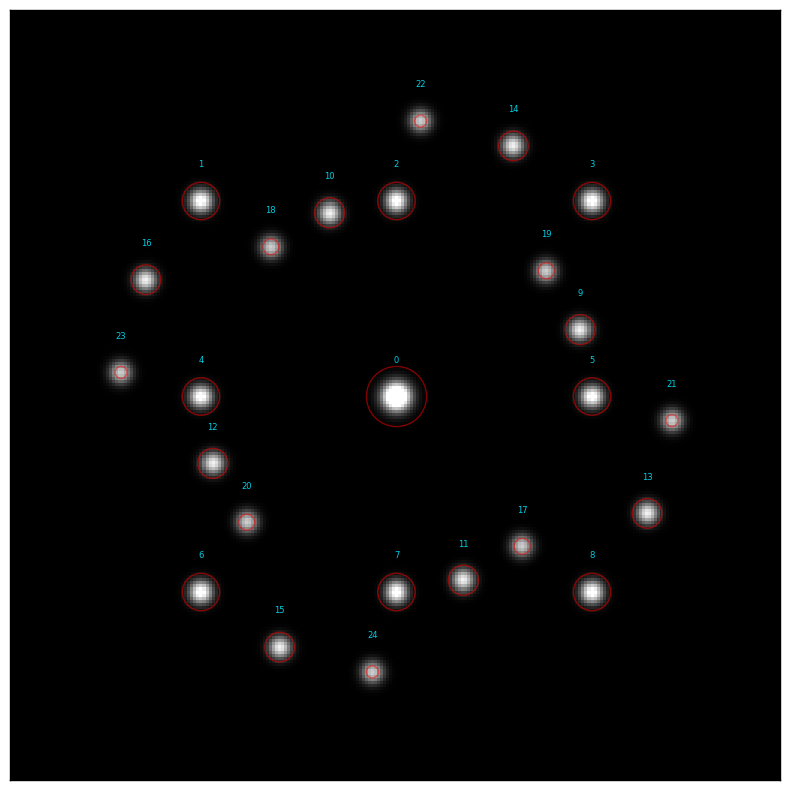

In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if DATA_FILE is None:
    image, known_origin, known_bases = three_lattice_image()
    im_bin = em.core.datastructures.dataset2d.Dataset2d.from_array(image)
    source_file, bin_factor = "synthetic three-lattice demonstration", 1
else:
    im_bin = em.io.read_2d(str(DATA_FILE), file_type="digitalmicrograph").bin(BIN_FACTOR, reducer="mean")
    image = np.asarray(im_bin.array, dtype=np.float32)
    source_file, bin_factor = str(DATA_FILE), BIN_FACTOR
moire = DiffractionMoire.from_data(im_bin)
moire.find_peaks(**PEAK_SETTINGS, plot_labels=True, plot_label_top_k=120, **DISPLAY)
print("Detected peaks:", len(moire.peaks))

## Choose three bases

For the synthetic example only, known seed locations are matched to detected peaks. For experimental data the original verbose detector output is saved to `auto_detection.log`.

[origin, u1, v1, u2, v2, u3, v3] = [0, 5, 7, 9, 11, 19, 17]


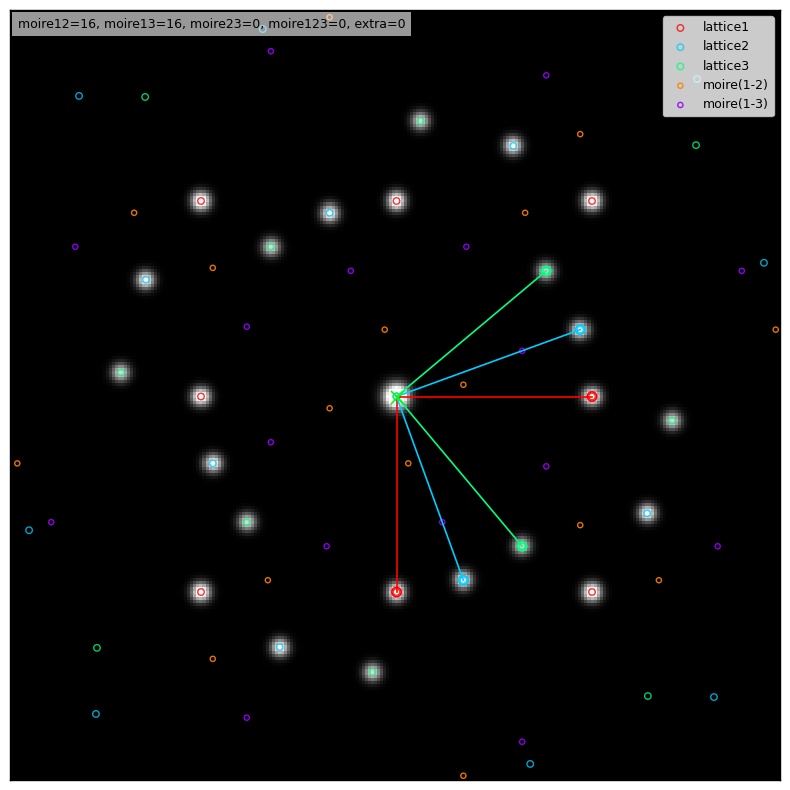

In [4]:
if MANUAL_INDICES is not None:
    vector_indices = sanitize_vector_indices(MANUAL_INDICES)
elif DATA_FILE is None:
    seed_locations = np.vstack([known_origin, *[known_origin + v for pair in known_bases for v in pair]])
    vector_indices = np.argmin(np.linalg.norm(moire.peaks[None, :, :] - seed_locations[:, None, :], axis=2), axis=1).tolist()
else:
    np.random.seed(0)
    with (OUTPUT_DIR / "auto_detection.log").open("w") as log, redirect_stdout(log):
        vector_indices = sanitize_vector_indices(moire.auto_find_lattice_vectors(num=3))
if len(vector_indices) != 7:
    raise ValueError("Automatic selection did not return three bases. Inspect auto_detection.log and set MANUAL_INDICES.")
print("[origin, u1, v1, u2, v2, u3, v3] =", vector_indices)
auto_init = get_auto_init_from_moire_three(moire, vector_indices)
vectors = {key: value for key, value in auto_init.items() if key.endswith("_rc")}
preview = moire.three_lattice_vectors(
    ind_origin=vector_indices[0], ind_u1=vector_indices[1], ind_v1=vector_indices[2],
    ind_u2=vector_indices[3], ind_v2=vector_indices[4], ind_u3=vector_indices[5], ind_v3=vector_indices[6],
    moire_draw=True, moire_parent_maxlen_px=75 if DATA_FILE is None else 240,
    draw_moire23=False, return_peaks=True, **DISPLAY,
)

## Build the original three-lattice fitter

The synthetic demonstration uses a smaller displacement cutoff and template size. Experimental settings below match the old notebook. The original fitter defaults remain unchanged.

In [5]:
build_settings = dict(
    center_radius_px=9, spot_radius_px=5, origin_delta_px=6.0, uv_delta_px=4.0,
    lattice_order=6, center_intensity=1.0, spot_intensity=0.12, moire_intensity=0.02,
    max_tile=None, draw_moire12=True, draw_moire13=True, draw_moire23=False,
    draw_moire123=False, draw_moire123_extra=False, moire_exclude_radius_px=2.0,
    moire_parent_maxlen_px=240.0, moire_round_decimals=3,
    gaussian_bg_sigma=70.0, gaussian_bg_intensity=0.03, dc_bg_intensity=0.005,
    refine_center_template=False, refine_spot_templates=True, refine_moire_template=True,
    tv_weight=1e-4, boundary_px=7.0,
)
if DATA_FILE is None:
    build_settings.update(center_radius_px=4, spot_radius_px=3, lattice_order=2,
                          max_tile=4, moire_parent_maxlen_px=75.0)
fitter = TripleLatticeMoireFitter(image, device=DEVICE, dtype=torch.float32, loss_mode="log1p")
fitter.set_mask(make_center_weight_mask(image.shape, vectors["origin_rc"], 12, center_weight=0.20))
fitter.build_from_auto_init(**vectors, peak_seed_rc=moire.peaks[vector_indices[1:]], **build_settings)
initial_summary, initial_render = fitter.summary(), fitter.render_numpy()

## Fit and inspect

Quick mode runs three steps per stage and is not a converged analysis. Set `QUICK_RUN=False` to use the original 40/120/120 iteration schedule.


[Stage 1] geometry + intensity + background


step    1/3 | loss=2.009983e-03 | data=1.954378e-03 | reg=5.560478e-05
step    3/3 | loss=8.655654e-04 | data=8.099606e-04 | reg=5.560477e-05

[Stage 2] release parent spot templates
step    1/3 | loss=5.787936e-04 | data=5.231888e-04 | reg=5.560477e-05
step    3/3 | loss=6.211963e-04 | data=5.655915e-04 | reg=5.560477e-05

[Stage 3] final refinement + three-lattice moire term
step    1/3 | loss=1.950066e-04 | data=1.394018e-04 | reg=5.560477e-05 | moire_scale=0.0000
step    3/3 | loss=1.862249e-04 | data=1.363075e-04 | reg=4.991744e-05 | moire_scale=0.0000


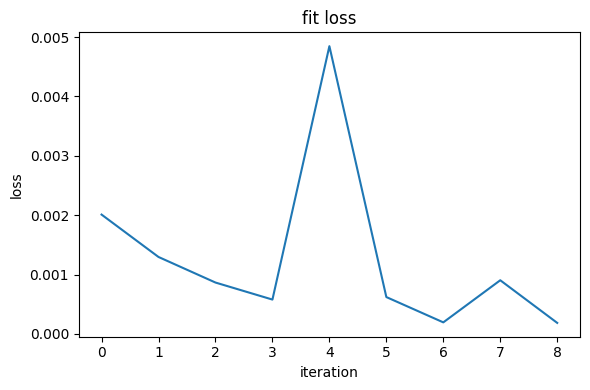

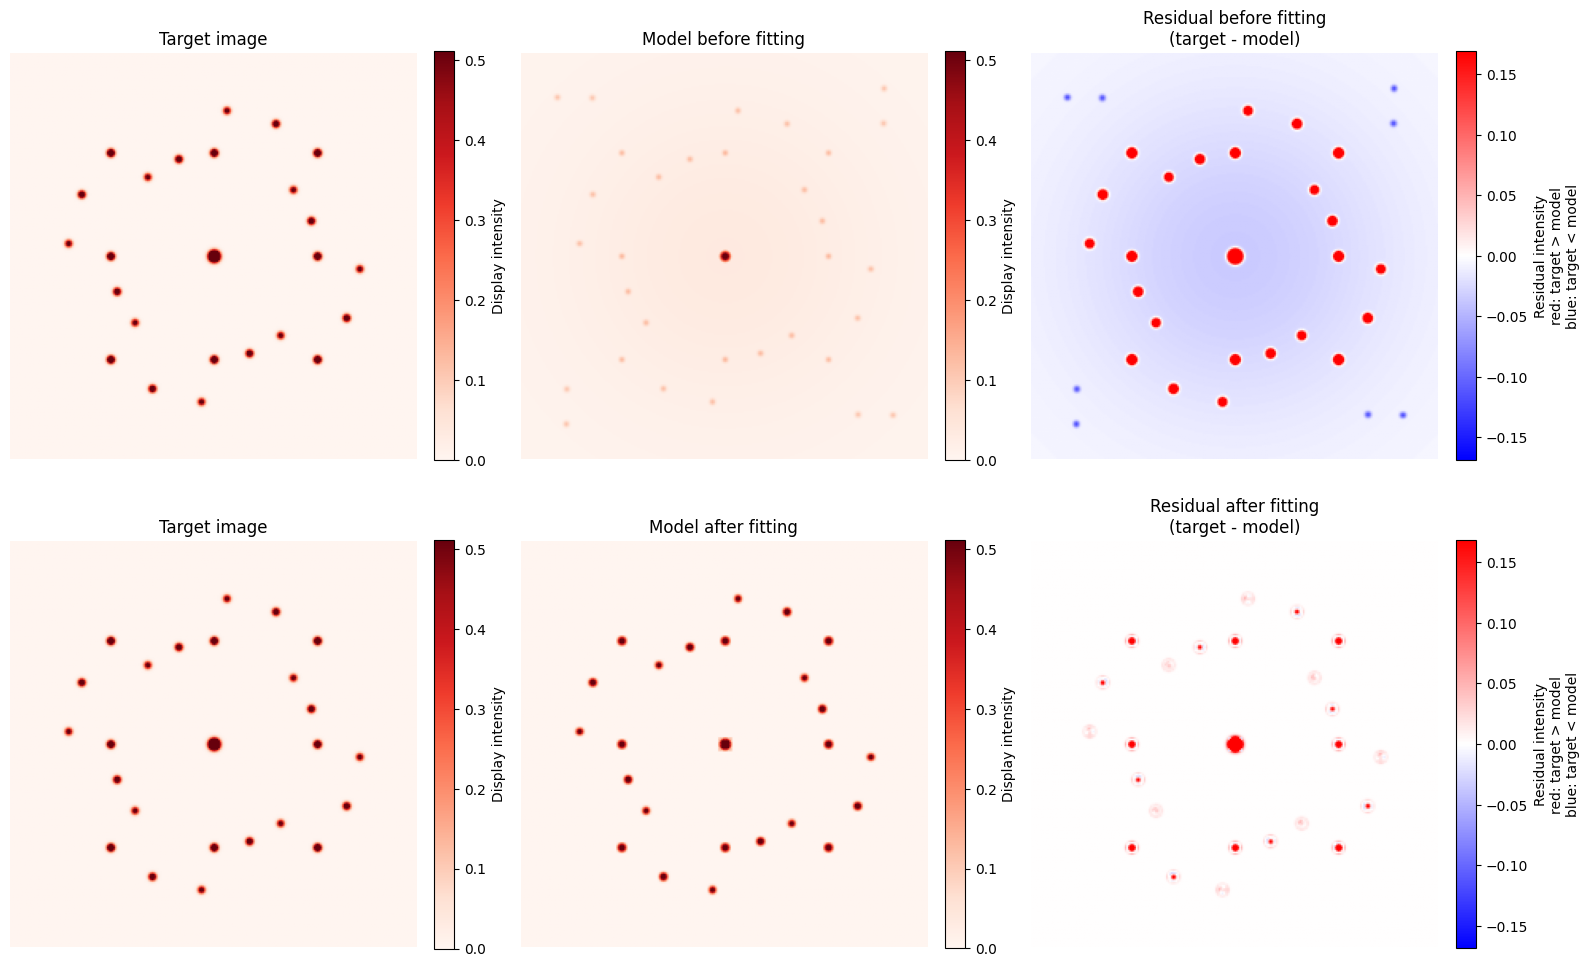

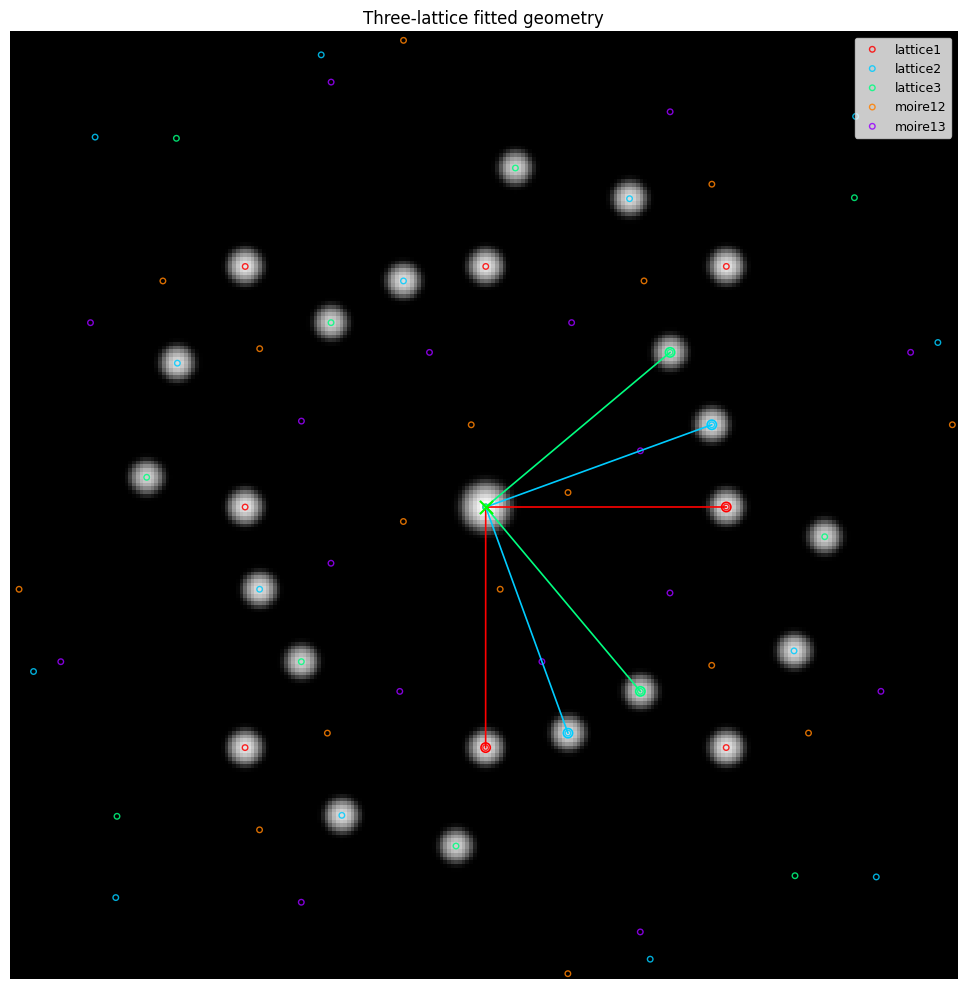

In [6]:
steps = (3, 3, 3) if QUICK_RUN else (40, 120, 120)
stage_settings = dict(stage1_steps=steps[0], stage2_steps=steps[1], stage3_steps=steps[2],
                      lr1=2e-1, lr2=5e-2, lr3=2e-2, constraint_weight=1.0)
fitter.fit_staged(**stage_settings)
refined_summary = fitter.summary()
fitter.plot_loss()
plot_before_after_models(fitter.image, initial_render, fitter.render_numpy())
plot_refined_overlay_three(image, refined_summary, title="Three-lattice fitted geometry")

## Save the independent tri result

In [7]:
save_fit_result(
    OUTPUT_DIR / "fit.npz", refined_summary, sampling=im_bin.sampling, units=im_bin.units,
    source_file=source_file, bin_factor=bin_factor, image_shape=image.shape,
    initial_summary=initial_summary, loss_history=fitter.loss_history,
    fit_settings=dict(model="tri", quick_run=QUICK_RUN, synthetic=DATA_FILE is None,
                      build=build_settings, stages=stage_settings,
                      peak_settings=PEAK_SETTINGS, vector_indices=vector_indices),
)
print("Saved:", OUTPUT_DIR / "fit.npz")

Saved: /Users/hu/Project/Moire/Morie/Moire_CDW/outputs/tri/fit.npz
